# Fitness Tracker Data Analysis Project

**Problem Statement:** As a data analyst for a fitness wearable company, analyze one year of
daily activity data from 60 users to uncover patterns in activity, sleep, and mood — clean the
messy raw sensor data, engineer per-user summary statistics, and visualize trends that could
inform product and health recommendations.

**Dataset:** `fitness_tracker_data.csv` — 21,940 rows (60 users x 365 days), 16 columns.

**Topics covered:**
1. Python essentials — functions, OOP, list/dict comprehensions
2. NumPy — arrays, broadcasting, vectorized operations
3. Pandas — dataframes, cleaning, merging, groupby
4. Data visualization — Matplotlib, Seaborn


## 1. Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)


## 2. Load & Inspect the Data

In [2]:
df = pd.read_csv("fitness_tracker_data.csv")

print("Shape:", df.shape)
df.head()


Shape: (21940, 16)


,user_id,name,age,gender,fitness_level,date,steps,active_minutes,calories_burned,sleep_hours,resting_heart_rate,weight_kg,water_intake_l,mood_score,stress_level,workout_type
0,U1001,Meera Nair,57,Female,Advanced,01-Jan-2024,5625.0,40,1855.1,5.36,59.5,66.8,1.80,4.0,4,Cycling
1,U1001,Meera Nair,57,Female,Advanced,02-Jan-2024,6934.0,53,1975.3,5.99,65.8,66.8,2.11,4.0,1,Swimming
2,U1001,Meera Nair,57,Female,Advanced,03-Jan-2024,4696.0,41,1816.2,6.59,63.6,66.8,2.61,NaN,3,Walking
3,U1001,Meera Nair,57,Female,Advanced,2024-01-04,7017.0,60,2051.0,6.28,71.1,66.8,2.72,6.0,5,Walking
4,U1001,Meera Nair,57,Female,Advanced,2024-01-05,3784.0,29,1807.7,5.09,53.0,66.8,2.23,5.0,4,NaN


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 21940 entries, 0 to 21939
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             21940 non-null  str    
 1   name                21940 non-null  str    
 2   age                 21940 non-null  int64  
 3   gender              21940 non-null  str    
 4   fitness_level       21940 non-null  str    
 5   date                21940 non-null  str    
 6   steps               21083 non-null  float64
 7   active_minutes      21940 non-null  int64  
 8   calories_burned     21940 non-null  float64
 9   sleep_hours         21284 non-null  float64
 10  resting_heart_rate  21940 non-null  float64
 11  weight_kg           21940 non-null  float64
 12  water_intake_l      21940 non-null  float64
 13  mood_score          20860 non-null  float64
 14  stress_level        21940 non-null  int64  
 15  workout_type        19490 non-null  str    
dtypes: float64(7), 

In [4]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,21940,60,U1008,368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,21940,57,Neha Verma,733,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,21940.0,NaN,NaN,NaN,39.618778,12.361356,18.0,29.0,42.0,52.0,59.0
gender,21940,3,Female,8043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fitness_level,21940,3,Advanced,8041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,21940,1095,28/08/2024,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
steps,21083.0,NaN,NaN,NaN,7040.532752,2784.954371,0.0,5125.0,7048.0,8958.5,18234.0
active_minutes,21940.0,NaN,NaN,NaN,53.692434,22.752643,0.0,38.0,54.0,69.0,149.0
calories_burned,21940.0,NaN,NaN,NaN,2239.302466,2160.51997,1354.1,1841.9,1982.05,2124.525,26175.0
sleep_hours,21284.0,NaN,NaN,NaN,7.051714,1.31513,2.37,6.15,7.04,7.94,12.07


In [5]:
# Check for missing values and duplicates before cleaning
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
 user_id                  0
name                     0
age                      0
gender                   0
fitness_level            0
date                     0
steps                  857
active_minutes           0
calories_burned          0
sleep_hours            656
resting_heart_rate       0
weight_kg                0
water_intake_l           0
mood_score            1080
stress_level             0
workout_type          2450
dtype: int64

Duplicate rows: 40


## 3. Data Cleaning (Python Functions + Pandas)

In [6]:
def parse_mixed_date(date_str):
    """Parse a date string that may be in one of several known formats."""
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"):
        try:
            return pd.to_datetime(date_str, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT


def cap_outliers(series, n_std=3):
    """Replace values beyond n standard deviations from the mean with NaN."""
    mean, std = series.mean(), series.std()
    upper_bound = mean + n_std * std
    return series.where(series <= upper_bound, np.nan)


def fill_missing_by_user(dataframe, column):
    """Fill missing values in `column` using each user's own median."""
    return dataframe.groupby("user_id")[column].transform(lambda s: s.fillna(s.median()))


In [7]:
# Standardize dates
df["date"] = df["date"].apply(parse_mixed_date)
print("Unparseable dates after cleaning:", df["date"].isna().sum())

# Drop exact duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows")

# Fix impossible negative heart rate readings
df["resting_heart_rate"] = df["resting_heart_rate"].abs()

# Cap extreme calorie sensor glitches, then treat as missing
outlier_count = (df["calories_burned"] > df["calories_burned"].mean() + 3*df["calories_burned"].std()).sum()
df["calories_burned"] = cap_outliers(df["calories_burned"])
print(f"Flagged {outlier_count} calorie outliers as missing")


Unparseable dates after cleaning: 0
Removed 40 duplicate rows
Flagged 323 calorie outliers as missing


In [8]:
# Fill missing numeric values using each user's own median (personalized imputation)
for col in ["steps", "sleep_hours", "calories_burned"]:
    df[col] = fill_missing_by_user(df, col)

# Fill remaining scattered missing values with overall median / a category
df["mood_score"] = df["mood_score"].fillna(df["mood_score"].median())
df["workout_type"] = df["workout_type"].fillna("Rest Day")

print("Missing values after cleaning:\n", df.isna().sum())


Missing values after cleaning:
 user_id               0
name                  0
age                   0
gender                0
fitness_level         0
date                  0
steps                 0
active_minutes        0
calories_burned       0
sleep_hours           0
resting_heart_rate    0
weight_kg             0
water_intake_l        0
mood_score            0
stress_level          0
workout_type          0
dtype: int64


In [9]:
# Sort and reset index for a tidy final dataframe
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)
df.head()


,user_id,name,age,gender,fitness_level,date,steps,active_minutes,calories_burned,sleep_hours,resting_heart_rate,weight_kg,water_intake_l,mood_score,stress_level,workout_type
0,U1001,Meera Nair,57,Female,Advanced,2024-01-01,5625.0,40,1855.1,5.36,59.5,66.8,1.80,4.0,4,Cycling
1,U1001,Meera Nair,57,Female,Advanced,2024-01-02,6934.0,53,1975.3,5.99,65.8,66.8,2.11,4.0,1,Swimming
2,U1001,Meera Nair,57,Female,Advanced,2024-01-03,4696.0,41,1816.2,6.59,63.6,66.8,2.61,6.0,3,Walking
3,U1001,Meera Nair,57,Female,Advanced,2024-01-04,7017.0,60,2051.0,6.28,71.1,66.8,2.72,6.0,5,Walking
4,U1001,Meera Nair,57,Female,Advanced,2024-01-05,3784.0,29,1807.7,5.09,53.0,66.8,2.23,5.0,4,Rest Day


## 4. List & Dict Comprehensions

Quick exploratory transformations using comprehensions instead of loops.

In [10]:
# List comprehension: unique real workout types (excluding rest days)
workout_types = [w for w in df["workout_type"].unique() if w != "Rest Day"]
print("Workout types:", workout_types)

# List comprehension: users who average over 8000 steps/day
user_avg_steps = df.groupby("user_id")["steps"].mean()
active_users = [uid for uid, avg in user_avg_steps.items() if avg > 8000]
print(f"\nUsers averaging 8000+ steps/day: {len(active_users)} -> {active_users[:5]}...")


Workout types: ['Cycling', 'Swimming', 'Walking', 'Strength Training', 'HIIT', 'Running', 'Pilates', 'Yoga']

Users averaging 8000+ steps/day: 23 -> ['U1004', 'U1006', 'U1012', 'U1013', 'U1015']...


In [11]:
# Dict comprehension: map each user to an age bucket
user_ages = df.drop_duplicates("user_id")[["user_id", "age"]].values

age_bucket = {
    uid: ("Young (<30)" if age < 30 else "Mid (30-44)" if age < 45 else "Senior (45+)")
    for uid, age in user_ages
}

# Dict comprehension: map each workout type to how many times it occurs
workout_counts = {w: (df["workout_type"] == w).sum() for w in df["workout_type"].unique()}

print("Sample age buckets:", dict(list(age_bucket.items())[:5]))
print("\nWorkout counts:", workout_counts)


Sample age buckets: {'U1001': 'Senior (45+)', 'U1002': 'Mid (30-44)', 'U1003': 'Young (<30)', 'U1004': 'Senior (45+)', 'U1005': 'Senior (45+)'}

Workout counts: {'Cycling': np.int64(2393), 'Swimming': np.int64(2407), 'Walking': np.int64(2466), 'Rest Day': np.int64(2446), 'Strength Training': np.int64(2425), 'HIIT': np.int64(2341), 'Running': np.int64(2436), 'Pilates': np.int64(2521), 'Yoga': np.int64(2465)}


## 5. Object-Oriented Programming

A `FitnessTracker` class wraps the cleaned dataframe and exposes reusable analysis methods —
this is how you'd structure this logic in a real project instead of scattering functions.

In [12]:
class FitnessTracker:
    """Encapsulates analysis operations on the cleaned fitness dataset."""

    def __init__(self, data: pd.DataFrame):
        self.data = data

    def user_summary(self, user_id: str) -> dict:
        """Return average key metrics for a single user."""
        sub = self.data[self.data["user_id"] == user_id]
        if sub.empty:
            raise ValueError(f"No records found for user_id={user_id}")
        return {
            "avg_steps": round(sub["steps"].mean(), 1),
            "avg_sleep_hours": round(sub["sleep_hours"].mean(), 2),
            "avg_mood_score": round(sub["mood_score"].mean(), 2),
            "avg_resting_hr": round(sub["resting_heart_rate"].mean(), 1),
            "favorite_workout": sub.loc[sub["workout_type"] != "Rest Day", "workout_type"].mode().iloc[0]
                if (sub["workout_type"] != "Rest Day").any() else "None",
        }

    def monthly_trend(self, metric: str = "steps") -> pd.Series:
        """Average a metric grouped by calendar month across all users."""
        return self.data.groupby(self.data["date"].dt.month)[metric].mean()

    def top_users(self, metric: str = "steps", n: int = 5) -> pd.Series:
        """Return the top-n users ranked by average of a metric."""
        return self.data.groupby("user_id")[metric].mean().sort_values(ascending=False).head(n)

    def correlation_matrix(self, columns: list) -> pd.DataFrame:
        """Return correlations between chosen numeric columns."""
        return self.data[columns].corr()


tracker = FitnessTracker(df)


In [13]:
# Demo the class methods
print("User summary for U1001:")
print(tracker.user_summary("U1001"))

print("\nTop 5 users by average daily steps:")
print(tracker.top_users("steps", 5))


User summary for U1001:
{'avg_steps': np.float64(5810.5), 'avg_sleep_hours': np.float64(6.71), 'avg_mood_score': np.float64(5.85), 'avg_resting_hr': np.float64(63.2), 'favorite_workout': 'Pilates'}

Top 5 users by average daily steps:
user_id
U1027    11600.109589
U1012    10478.654795
U1017    10338.698630
U1043     9573.556164
U1060     9511.790411
Name: steps, dtype: float64


## 6. NumPy — Arrays, Broadcasting, Vectorized Operations

In [14]:
# Convert key columns to NumPy arrays for fast numeric work
steps_arr = df["steps"].to_numpy()
calories_arr = df["calories_burned"].to_numpy()
height_arr = df["age"].to_numpy()  # just for demonstration of array ops

print("Steps array dtype:", steps_arr.dtype, "| shape:", steps_arr.shape)
print("Mean steps:", steps_arr.mean().round(1))
print("Std steps:", steps_arr.std().round(1))


Steps array dtype: float64 | shape: (21900,)
Mean steps: 7038.8
Std steps: 2759.5


In [15]:
# Broadcasting example: compute BMI for a small array of heights/weights
# BMI = weight (kg) / height (m)^2  -- height needs to be converted from cm to m
heights_cm = np.array([170, 165, 180, 158, 172])
weights_kg = np.array([70, 60, 85, 50, 75])

heights_m = heights_cm / 100          # broadcasting: scalar divides whole array
bmi = weights_kg / heights_m ** 2     # elementwise vectorized division

for h, w, b in zip(heights_cm, weights_kg, bmi):
    print(f"Height={h}cm, Weight={w}kg -> BMI={b:.2f}")


Height=170cm, Weight=70kg -> BMI=24.22
Height=165cm, Weight=60kg -> BMI=22.04
Height=180cm, Weight=85kg -> BMI=26.23
Height=158cm, Weight=50kg -> BMI=20.03
Height=172cm, Weight=75kg -> BMI=25.35


In [16]:
# Vectorized outlier detection using z-scores (no explicit loops)
z_scores = (steps_arr - steps_arr.mean()) / steps_arr.std()
outlier_mask = np.abs(z_scores) > 3

print(f"Step-count outliers (|z| > 3): {outlier_mask.sum()} rows out of {len(steps_arr)}")
print("Example outlier step values:", np.sort(steps_arr[outlier_mask])[-5:])


Step-count outliers (|z| > 3): 34 rows out of 21900
Example outlier step values: [17002. 17160. 17640. 17880. 18234.]


In [17]:
# Vectorized feature engineering: calories burned per 1000 steps
cal_per_1000_steps = np.where(steps_arr > 0, calories_arr / (steps_arr / 1000), np.nan)
df["cal_per_1000_steps"] = cal_per_1000_steps

print("Average calories burned per 1000 steps:", np.nanmean(cal_per_1000_steps).round(2))


Average calories burned per 1000 steps: 372.88


/tmp/ipykernel_588/3331005597.py:2: RuntimeWarning: divide by zero encountered in divide
  cal_per_1000_steps = np.where(steps_arr > 0, calories_arr / (steps_arr / 1000), np.nan)


## 7. Pandas — GroupBy & Merging

In [18]:
# GroupBy: per-user average metrics
user_stats = df.groupby("user_id").agg(
    avg_steps=("steps", "mean"),
    avg_sleep=("sleep_hours", "mean"),
    avg_mood=("mood_score", "mean"),
    avg_resting_hr=("resting_heart_rate", "mean"),
    total_active_minutes=("active_minutes", "sum"),
).reset_index()

user_stats.sort_values("avg_steps", ascending=False).head(10)


,user_id,avg_steps,avg_sleep,avg_mood,avg_resting_hr,total_active_minutes
26,U1027,11600.109589,7.714904,6.515068,86.372603,32499
11,U1012,10478.654795,6.531945,5.887671,64.580548,29292
16,U1017,10338.698630,7.901918,6.449315,69.496164,28641
42,U1043,9573.556164,8.375123,6.720548,75.843562,26690
59,U1060,9511.790411,6.009425,5.652055,72.877534,26282
48,U1049,9509.265753,5.679356,5.386301,84.637260,26458
45,U1046,9470.443836,6.622849,5.687671,72.632877,26435
47,U1048,9396.501370,5.417945,5.331507,64.912055,26181
5,U1006,9377.294521,7.588041,6.336986,67.782192,25979
43,U1044,9152.372603,7.813397,6.356164,70.048767,25446


In [19]:
# GroupBy: monthly trend across all users
df["month"] = df["date"].dt.month
monthly_trend = df.groupby("month")[["steps", "sleep_hours", "mood_score"]].mean()
monthly_trend


,steps,sleep_hours,mood_score
month,,,
1,7057.018280,7.021820,6.006989
2,7011.045115,7.037264,6.040230
3,7074.108065,7.009040,6.047312
4,7001.224167,7.031944,6.035000
5,7004.778495,7.091852,6.080108
6,7058.267778,7.122444,6.082778
7,7002.490860,7.056215,6.057527
8,7050.405108,7.040844,6.016667
9,7036.437222,7.033456,6.005556


In [20]:
# GroupBy: average metrics by fitness level and workout type
fitness_workout_summary = df.groupby(["fitness_level", "workout_type"])["active_minutes"].mean().unstack()
fitness_workout_summary


workout_type,Cycling,HIIT,Pilates,Rest Day,Running,Strength Training,Swimming,Walking,Yoga
fitness_level,,,,,,,,,
Advanced,52.012865,53.385227,52.321429,52.841871,52.166480,51.505734,52.491111,51.109151,52.041157
Beginner,57.489071,57.538462,57.459893,56.459834,57.493036,55.256720,56.679272,55.870801,56.721024
Intermediate,52.813896,53.110828,52.247350,51.963680,53.184690,52.529048,52.989912,51.941401,52.141990


In [21]:
# Merge: attach each user's overall averages back onto every daily record
merged = df.merge(user_stats, on="user_id", suffixes=("", "_user_avg"))

# Feature: how much a given day's steps deviate from that user's own average
merged["steps_vs_personal_avg"] = merged["steps"] - merged["avg_steps"]

merged[["user_id", "date", "steps", "avg_steps", "steps_vs_personal_avg"]].head()


,user_id,date,steps,avg_steps,steps_vs_personal_avg
0,U1001,2024-01-01,5625.0,5810.473973,-185.473973
1,U1001,2024-01-02,6934.0,5810.473973,1123.526027
2,U1001,2024-01-03,4696.0,5810.473973,-1114.473973
3,U1001,2024-01-04,7017.0,5810.473973,1206.526027
4,U1001,2024-01-05,3784.0,5810.473973,-2026.473973


## 8. Data Visualization — Matplotlib & Seaborn

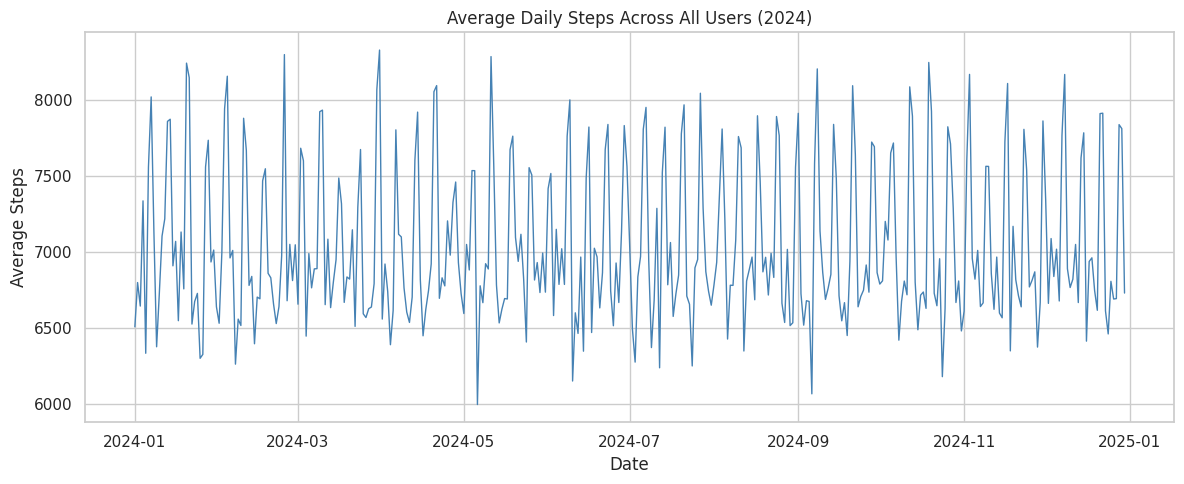

In [22]:
# Matplotlib: overall daily steps trend across the year (all users averaged)
daily_avg = df.groupby("date")["steps"].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_avg.index, daily_avg.values, color="steelblue", linewidth=1)
plt.title("Average Daily Steps Across All Users (2024)")
plt.xlabel("Date")
plt.ylabel("Average Steps")
plt.tight_layout()
plt.show()


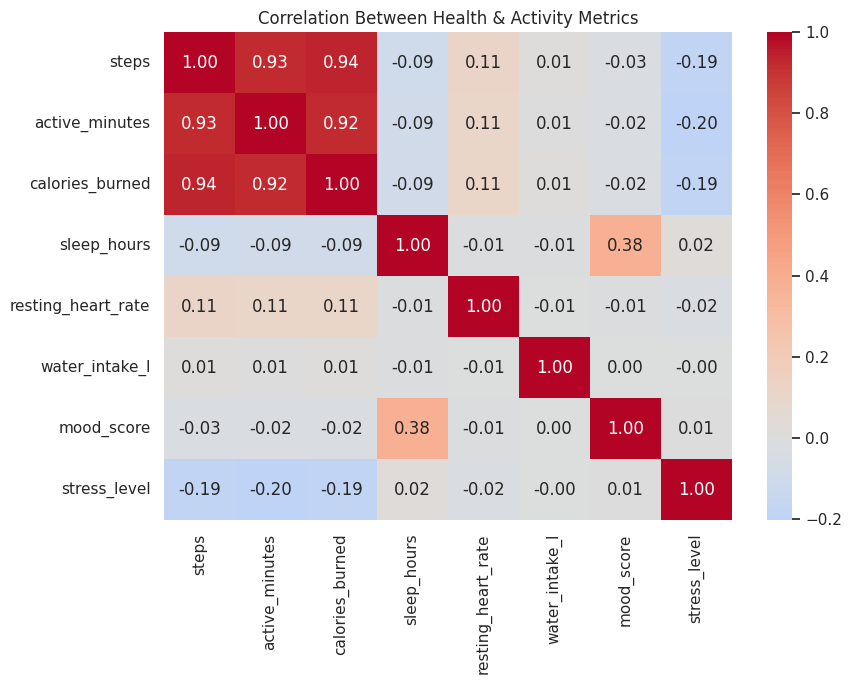

In [23]:
# Seaborn: correlation heatmap between key numeric metrics
numeric_cols = ["steps", "active_minutes", "calories_burned", "sleep_hours",
                 "resting_heart_rate", "water_intake_l", "mood_score", "stress_level"]

corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Health & Activity Metrics")
plt.tight_layout()
plt.show()


/tmp/ipykernel_588/3307264770.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="fitness_level", y="sleep_hours",


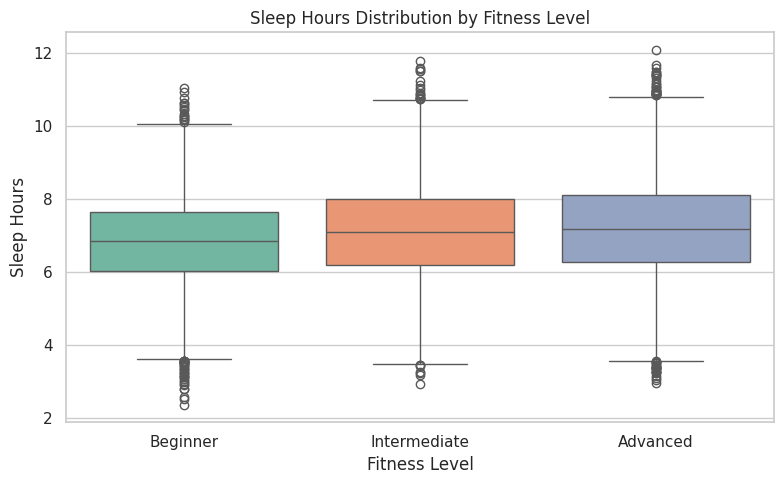

In [24]:
# Seaborn: boxplot of sleep hours by fitness level
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="fitness_level", y="sleep_hours",
            order=["Beginner", "Intermediate", "Advanced"], palette="Set2")
plt.title("Sleep Hours Distribution by Fitness Level")
plt.xlabel("Fitness Level")
plt.ylabel("Sleep Hours")
plt.tight_layout()
plt.show()


/tmp/ipykernel_588/1546860749.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette="viridis")


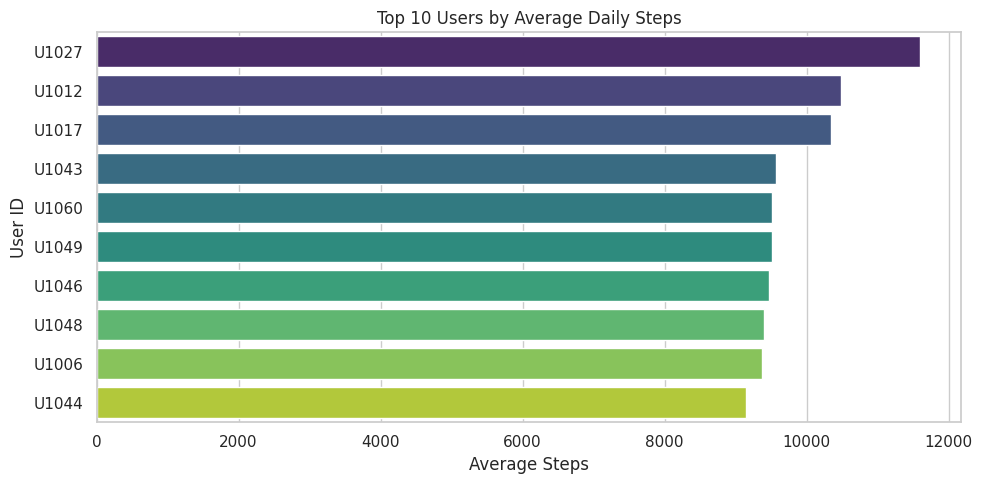

In [25]:
# Seaborn: bar chart of top 10 users by average steps
top10 = tracker.top_users("steps", 10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10.values, y=top10.index, palette="viridis")
plt.title("Top 10 Users by Average Daily Steps")
plt.xlabel("Average Steps")
plt.ylabel("User ID")
plt.tight_layout()
plt.show()


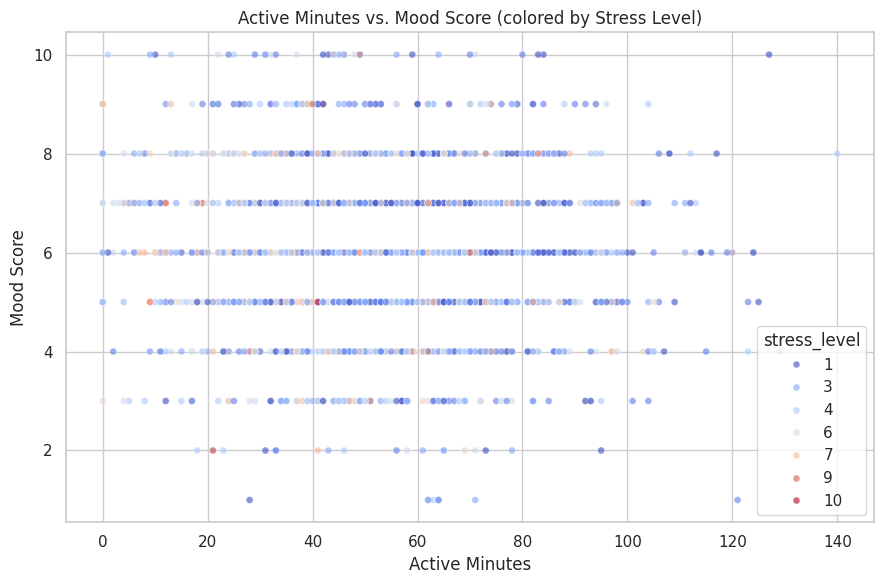

In [26]:
# Seaborn: scatter plot of active minutes vs. mood score, colored by stress level
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df.sample(2000, random_state=1), x="active_minutes", y="mood_score",
                 hue="stress_level", palette="coolwarm", alpha=0.6, s=25)
plt.title("Active Minutes vs. Mood Score (colored by Stress Level)")
plt.xlabel("Active Minutes")
plt.ylabel("Mood Score")
plt.tight_layout()
plt.show()


/tmp/ipykernel_588/2220183338.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df[df["workout_type"] != "Rest Day"], y="workout_type",


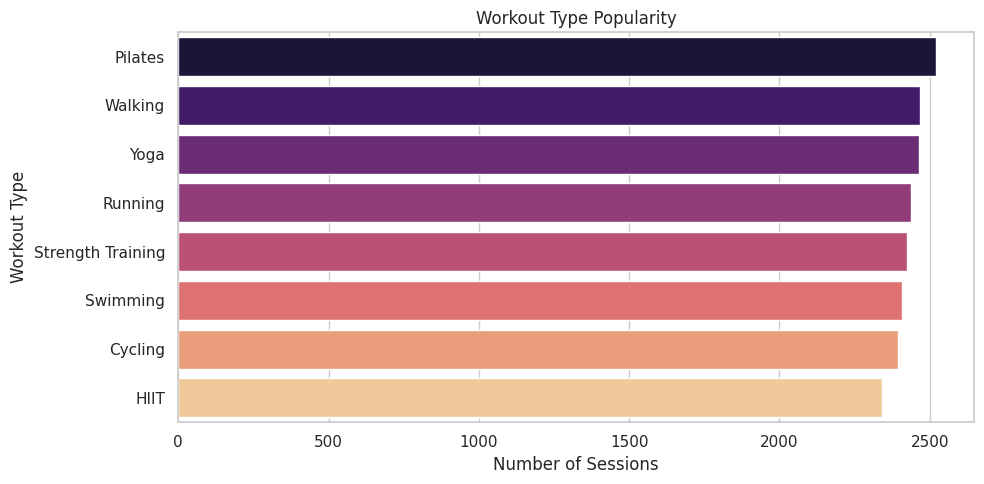

In [27]:
# Seaborn: count of workout type preferences
plt.figure(figsize=(10, 5))
workout_order = df[df["workout_type"] != "Rest Day"]["workout_type"].value_counts().index
sns.countplot(data=df[df["workout_type"] != "Rest Day"], y="workout_type",
              order=workout_order, palette="magma")
plt.title("Workout Type Popularity")
plt.xlabel("Number of Sessions")
plt.ylabel("Workout Type")
plt.tight_layout()
plt.show()


## 9. Key Insights (Summary)

Fill this in after reviewing the plots above — for example:
- Which season/month has the highest average activity?
- Which fitness level sleeps the most/least?
- How strongly does sleep correlate with mood or stress?
- Which workout type is most popular, and does it vary by fitness level?

This closing section is where you translate the analysis into a short written summary for
stakeholders — a key part of any real data project.